# 06 · Categorical Data Analysis and Logistic Regression

**Syllabus:** Unit 4. Contingency tables, chi-squared test for independence, odds ratio, logit, logistic regression (interpretation, inference), sensitivity, specificity and ROC curves.

**Question:** what makes a day **unhealthy** (PM2.5 > 60 µg/m³, the CPCB 24-hour standard), and can we predict it from the other pollutants?

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
%matplotlib inline

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

PREDICTORS = ["PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
df = pd.read_csv(ROOT / "data" / "processed" / "bengaluru_clean.csv", parse_dates=["Date"]).rename(columns={"PM2.5": "PM25"})
df = df.dropna(subset=["PM25"]).reset_index(drop=True)
df["Weekend"] = np.where(df["Date"].dt.dayofweek >= 5, "Weekend", "Weekday")
df["Winter"] = (df["Season"] == "Winter").astype(int)
df["Status"] = np.where(df["Unhealthy"] == 1, "Unhealthy", "Acceptable")
print(f"Days with PM2.5: {len(df)} | unhealthy: {df.Unhealthy.sum()} ({df.Unhealthy.mean():.1%})")

Days with PM2.5: 1649 | unhealthy: 149 (9.0%)


# Part A: Contingency tables

## 2. Season × air quality status

**Chi-squared test for independence.** H₀: air quality status does not depend on season.

$$\chi^2 = \sum \frac{(O - E)^2}{E}, \qquad E_{ij} = \frac{\text{row}_i \times \text{col}_j}{n}, \qquad df = (r-1)(c-1)$$

In [2]:
ORDER = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
obs = pd.crosstab(df["Season"], df["Status"]).reindex(ORDER)
chi2, p, dof, expected = stats.chi2_contingency(obs)
expected = pd.DataFrame(expected, index=obs.index, columns=obs.columns)

table = obs.copy()
table["Total"] = table.sum(axis=1)
table["% unhealthy"] = (obs["Unhealthy"] / table["Total"] * 100).round(1)
table.to_csv(TAB / "contingency_season_status.csv")
display(table)
print("Expected counts under H0:")
display(expected.round(1))

n = obs.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(obs.shape) - 1)))
print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")
print("Smallest expected count:", round(expected.values.min(), 1), "(all >= 5, so the chi-square approximation is valid)")

Status,Acceptable,Unhealthy,Total,% unhealthy
Season,,,,
Winter,355,86,441,19.5000
Summer,414,30,444,6.8000
Monsoon,495,1,496,0.2000
Post-monsoon,236,32,268,11.9000


Expected counts under H0:


Status,Acceptable,Unhealthy
Season,,
Winter,401.2000,39.8000
Summer,403.9000,40.1000
Monsoon,451.2000,44.8000
Post-monsoon,243.8000,24.2000


Chi-square = 111.42, df = 3, p = 5.44e-24, Cramér's V = 0.260
Smallest expected count: 24.2 (all >= 5, so the chi-square approximation is valid)


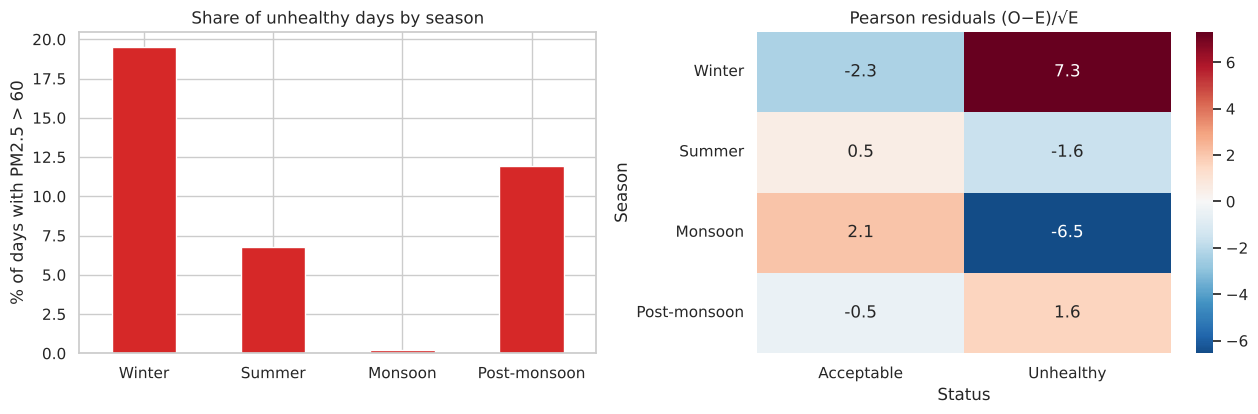

In [3]:
std_resid = (obs - expected) / np.sqrt(expected)
std_resid.round(2).to_csv(TAB / "contingency_season_residuals.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
(table["% unhealthy"]).plot.bar(ax=axes[0], color="#d62828")
axes[0].set(title="Share of unhealthy days by season", ylabel="% of days with PM2.5 > 60", xlabel="")
axes[0].tick_params(axis="x", rotation=0)
sns.heatmap(std_resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Pearson residuals (O−E)/√E")
fig.tight_layout(); fig.savefig(FIG / "19_contingency_season.png", dpi=150); plt.show()

**Pearson residuals** show *where* the dependence is: cells above +2 have many more cases than independence predicts, cells below −2 far fewer.

## 3. Odds ratios (2 × 2 tables)

Odds of an unhealthy day = P(unhealthy) / P(acceptable). The **odds ratio** compares two groups:

$$OR = \frac{a\,d}{b\,c}, \qquad SE[\ln OR] = \sqrt{\tfrac1a + \tfrac1b + \tfrac1c + \tfrac1d}, \qquad 95\%\ CI = \exp(\ln OR \pm 1.96\,SE)$$

OR = 1 means no association. Two comparisons: **winter vs other seasons**, and **weekday vs weekend** (a proxy for traffic and work activity).

In [4]:
def odds_ratio_table(exposed, label_exposed, label_other):
    a = int(((exposed) & (df.Unhealthy == 1)).sum()); b = int(((exposed) & (df.Unhealthy == 0)).sum())
    c = int(((~exposed) & (df.Unhealthy == 1)).sum()); d = int(((~exposed) & (df.Unhealthy == 0)).sum())
    or_ = (a * d) / (b * c)
    se = np.sqrt(1/a + 1/b + 1/c + 1/d)
    lo, hi = np.exp(np.log(or_) - 1.96 * se), np.exp(np.log(or_) + 1.96 * se)
    chi2, p, _, _ = stats.chi2_contingency([[a, b], [c, d]])
    fisher_p = stats.fisher_exact([[a, b], [c, d]])[1]
    return {
        "comparison": f"{label_exposed} vs {label_other}",
        "unhealthy / acceptable (exposed)": f"{a} / {b}",
        "unhealthy / acceptable (other)": f"{c} / {d}",
        "odds (exposed)": a / b, "odds (other)": c / d,
        "odds ratio": or_, "95% CI low": lo, "95% CI high": hi,
        "risk ratio": (a / (a + b)) / (c / (c + d)),
        "chi-square p": p, "Fisher exact p": fisher_p,
    }

ors = pd.DataFrame([
    odds_ratio_table(df.Season == "Winter", "Winter", "other seasons"),
    odds_ratio_table(df.Weekend == "Weekday", "Weekday", "weekend"),
]).set_index("comparison")
ors.to_csv(TAB / "odds_ratios.csv")
ors.T

comparison,Winter vs other seasons,Weekday vs weekend
unhealthy / acceptable (exposed),86 / 355,110 / 1065
unhealthy / acceptable (other),63 / 1145,39 / 435
odds (exposed),0.2423,0.1033
odds (other),0.0550,0.0897
odds ratio,4.4029,1.1520
95% CI low,3.1146,0.7863
95% CI high,6.2240,1.6879
risk ratio,3.7393,1.1378
chi-square p,0.0000,0.5274
Fisher exact p,0.0000,0.5072


# Part B: Logistic regression

The response is binary, so a linear model would predict probabilities outside [0, 1]. Logistic regression models the **log-odds (logit)**:

$$\text{logit}(\pi) = \ln\frac{\pi}{1-\pi} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k, \qquad \pi = \frac{1}{1+e^{-(\beta_0+\boldsymbol\beta^\top \mathbf x)}}$$

It is fitted by **maximum likelihood**. $e^{\beta_j}$ is the **odds ratio** for a one-unit rise in $x_j$, holding the other variables fixed.

**Design choices**
- Same chronological train/test split as the regression notebooks.
- Season enters as a single **Winter** indicator. The monsoon has only 1 unhealthy day in the whole dataset, so a separate Monsoon dummy would be (almost) perfectly separated and its estimate would blow up.
- Only 7 of the 297 test days are unhealthy, so test-set metrics are noisy and are reported with that caveat.

In [5]:
data = df.dropna(subset=PREDICTORS).reset_index(drop=True)
SPLIT_DATE = pd.Timestamp(pd.read_csv(TAB / "train_test_split.csv")["SPLIT_DATE"][0])
train = data[data.Date < SPLIT_DATE].reset_index(drop=True)
test = data[data.Date >= SPLIT_DATE].reset_index(drop=True)
print(f"Train: {len(train)} days, {train.Unhealthy.sum()} unhealthy ({train.Unhealthy.mean():.1%})")
print(f"Test : {len(test)} days, {test.Unhealthy.sum()} unhealthy ({test.Unhealthy.mean():.1%})")

formula = "Unhealthy ~ " + " + ".join(PREDICTORS) + " + Winter"
logit = smf.logit(formula, data=train).fit(disp=False)
print(logit.summary())

Train: 1181 days, 127 unhealthy (10.8%)
Test : 297 days, 7 unhealthy (2.4%)
                           Logit Regression Results                           
Dep. Variable:              Unhealthy   No. Observations:                 1181
Model:                          Logit   Df Residuals:                     1171
Method:                           MLE   Df Model:                            9
Date:                Tue, 03 Nov 2026   Pseudo R-squ.:                  0.3678
Time:                        09:30:46   Log-Likelihood:                -254.83
converged:                       True   LL-Null:                       -403.11
Covariance Type:            nonrobust   LLR p-value:                 1.401e-58
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -9.1016      0.747    -12.179      0.000     -10.566      -7.637
PM10           0.0290      0.003      8.558      0.000 

## 4. Interpretation: odds ratios

Odds ratios are shown per **10 µg/m³** (per 1 mg/m³ for CO), which is a more meaningful step than 1 unit.

In [6]:
step = pd.Series({c: 10 for c in PREDICTORS} | {"CO": 1, "Winter": 1, "Intercept": 1})
ci = logit.conf_int()
or_table = pd.DataFrame({
    "coef (log-odds)": logit.params,
    "std err": logit.bse,
    "z": logit.tvalues,
    "p-value (Wald)": logit.pvalues,
    "step": step[logit.params.index],
})
or_table["odds ratio per step"] = np.exp(or_table["coef (log-odds)"] * or_table["step"])
or_table["OR 95% CI low"] = np.exp(ci[0] * or_table["step"])
or_table["OR 95% CI high"] = np.exp(ci[1] * or_table["step"])
or_table["significant 5%"] = or_table["p-value (Wald)"] < 0.05
or_table.to_csv(TAB / "logistic_odds_ratios.csv")
or_table.drop(index="Intercept").round(4)

,coef (log-odds),std err,z,p-value (Wald),step,odds ratio per step,OR 95% CI low,OR 95% CI high,significant 5%
PM10,0.0290,0.0034,8.5579,0.0000,10,1.3367,1.2508,1.4286,True
NO,-0.0105,0.0223,-0.4719,0.6370,10,0.9001,0.5812,1.3939,False
NO2,0.0265,0.0125,2.1264,0.0335,10,1.3037,1.0210,1.6647,True
NOx,0.0438,0.0088,4.9824,0.0000,10,1.5502,1.3046,1.8419,True
NH3,0.0092,0.0085,1.0819,0.2793,10,1.0961,0.9282,1.2943,False
CO,0.0475,0.1375,0.3452,0.7299,1,1.0486,0.8009,1.3728,False
SO2,0.1407,0.0531,2.6504,0.0080,10,4.0848,1.4428,11.5644,True
O3,0.0130,0.0072,1.7926,0.0730,10,1.1386,0.9879,1.3123,False
Winter,0.8326,0.2700,3.0838,0.0020,1,2.2992,1.3545,3.9030,True


## 5. Inference: likelihood-ratio tests and model fit

- **Overall LR test:** $G^2 = -2(\ell_0 - \ell_1) \sim \chi^2_k$ compares the model with the intercept-only model.
- **Drop-one LR tests:** does each variable improve the likelihood, given all the others? (More reliable than Wald tests with rare events.)
- **McFadden pseudo-R²** $= 1 - \ell_1/\ell_0$. Values of 0.2-0.4 indicate a good fit for logistic models.

In [7]:
print(f"LR chi2 = {logit.llr:.2f}, df = {int(logit.df_model)}, p = {logit.llr_pvalue:.2e}")
print(f"McFadden pseudo-R2 = {logit.prsquared:.3f} | AIC = {logit.aic:.1f} | BIC = {logit.bic:.1f}")

terms = PREDICTORS + ["Winter"]
lr_rows = []
for t in terms:
    reduced = smf.logit("Unhealthy ~ " + " + ".join([x for x in terms if x != t]), data=train).fit(disp=False)
    g2 = 2 * (logit.llf - reduced.llf)
    lr_rows.append({"term": t, "G2 (drop-one)": g2, "p-value": stats.chi2.sf(g2, 1)})
lr_tests = pd.DataFrame(lr_rows).set_index("term").sort_values("G2 (drop-one)", ascending=False)
lr_tests.to_csv(TAB / "logistic_lr_tests.csv")
lr_tests

LR chi2 = 296.56, df = 9, p = 1.40e-58
McFadden pseudo-R2 = 0.368 | AIC = 529.7 | BIC = 580.4


,G2 (drop-one),p-value
term,,
PM10,89.5473,0.0000
NOx,29.1035,0.0000
Winter,9.4734,0.0021
SO2,7.7618,0.0053
NO2,4.5302,0.0333
O3,3.2031,0.0735
NH3,1.0992,0.2944
NO,0.2269,0.6338
CO,0.1127,0.7371


## 6. Predicted probabilities

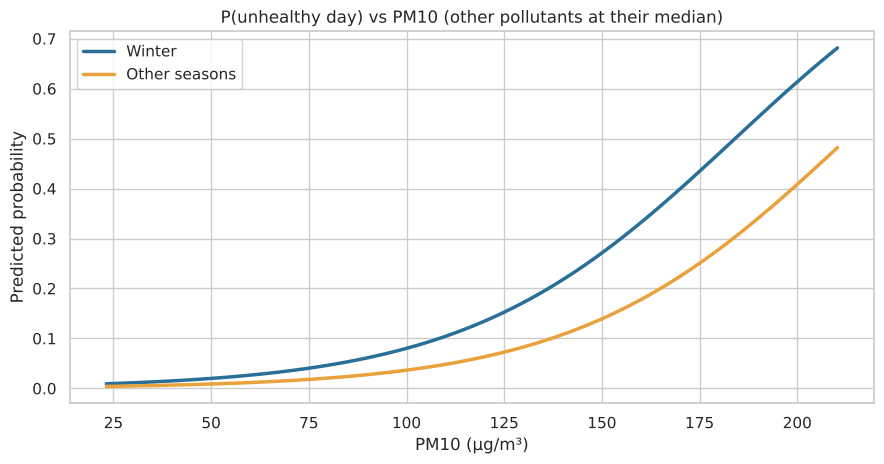

In [8]:
grid = pd.DataFrame({c: [train[c].median()] * 100 for c in PREDICTORS})
grid["PM10"] = np.linspace(train.PM10.quantile(0.01), train.PM10.quantile(0.99), 100)
fig, ax = plt.subplots(figsize=(9, 4.8))
for w, col, lab in [(1, "#2a6f97", "Winter"), (0, "#e9a23b", "Other seasons")]:
    g = grid.assign(Winter=w)
    ax.plot(g.PM10, logit.predict(g), color=col, lw=2.5, label=lab)
ax.set(title="P(unhealthy day) vs PM10 (other pollutants at their median)", xlabel="PM10 (µg/m³)", ylabel="Predicted probability")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "20_logistic_probability_curve.png", dpi=150); plt.show()

# Part C: Summarising predictive power

- **Sensitivity** (true positive rate) = TP / (TP + FN): the share of unhealthy days that are caught.
- **Specificity** (true negative rate) = TN / (TN + FP): the share of acceptable days correctly left alone.
- The **ROC curve** plots sensitivity against 1 − specificity for every threshold. **AUC** is the probability that a random unhealthy day gets a higher score than a random acceptable day (0.5 = guessing, 1 = perfect).

With only ~11% unhealthy days, the default 0.5 threshold misses many of them. For a **public-health warning**, missing an unhealthy day is worse than a false alarm, so the threshold is chosen on the *training* data by **Youden's J** = sensitivity + specificity − 1.

In [9]:
p_train = logit.predict(train)
p_test = logit.predict(test)
fpr, tpr, thr = roc_curve(train.Unhealthy, p_train)
youden_thr = thr[np.argmax(tpr - fpr)]
print(f"Youden-optimal threshold (from training data): {youden_thr:.3f}")

def classify_metrics(y, p, t, label):
    tn, fp, fn, tp = confusion_matrix(y, (p >= t).astype(int), labels=[0, 1]).ravel()
    return {"set / threshold": label, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "accuracy": (tp + tn) / len(y), "AUC": roc_auc_score(y, p)}

metrics = pd.DataFrame([
    classify_metrics(train.Unhealthy, p_train, 0.5, "Train @ 0.5"),
    classify_metrics(train.Unhealthy, p_train, youden_thr, f"Train @ {youden_thr:.2f} (Youden)"),
    classify_metrics(test.Unhealthy, p_test, 0.5, "Test @ 0.5"),
    classify_metrics(test.Unhealthy, p_test, youden_thr, f"Test @ {youden_thr:.2f} (Youden)"),
]).set_index("set / threshold")
metrics.to_csv(TAB / "logistic_classification_metrics.csv")
metrics

Youden-optimal threshold (from training data): 0.120


,TP,FN,FP,TN,sensitivity,specificity,precision,accuracy,AUC
set / threshold,,,,,,,,,
Train @ 0.5,47,80,13,1041,0.3701,0.9877,0.7833,0.9213,0.8944
Train @ 0.12 (Youden),104,23,196,858,0.8189,0.8140,0.3467,0.8146,0.8944
Test @ 0.5,2,5,3,287,0.2857,0.9897,0.4000,0.9731,0.9685
Test @ 0.12 (Youden),7,0,44,246,1.0000,0.8483,0.1373,0.8519,0.9685


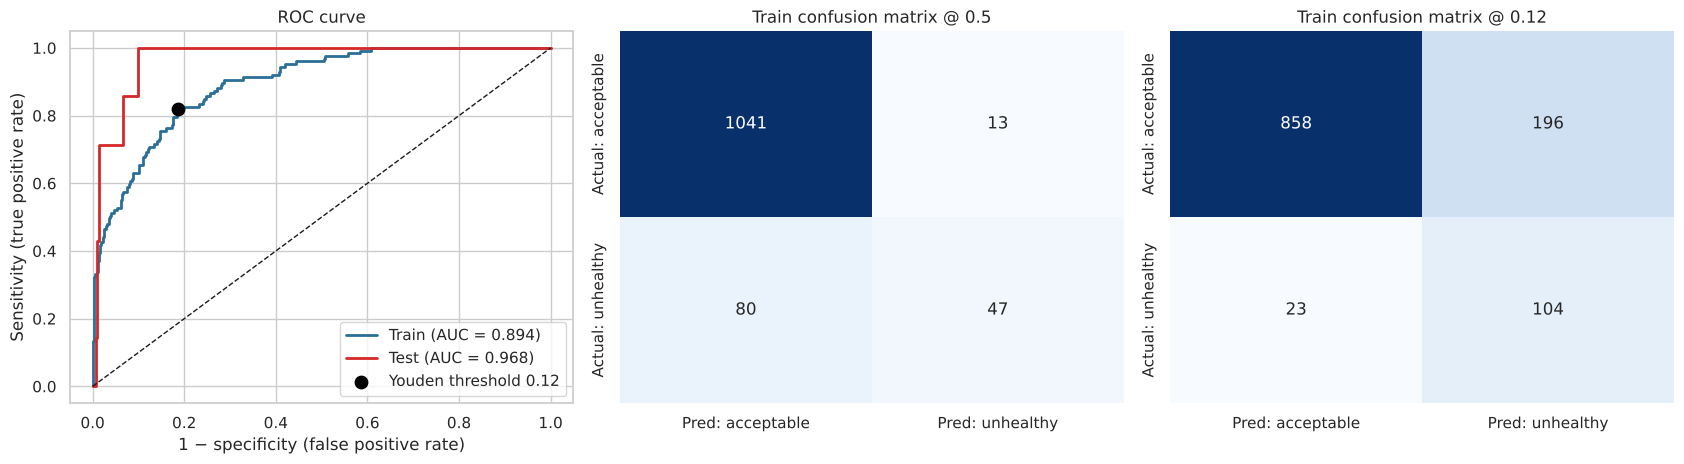

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for y, p, lab, col in [(train.Unhealthy, p_train, "Train", "#2a6f97"), (test.Unhealthy, p_test, "Test", "#d62828")]:
    f, t, _ = roc_curve(y, p)
    axes[0].plot(f, t, lw=2, color=col, label=f"{lab} (AUC = {roc_auc_score(y, p):.3f})")
j = np.argmax(tpr - fpr)
axes[0].scatter(fpr[j], tpr[j], s=80, color="black", zorder=5, label=f"Youden threshold {youden_thr:.2f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curve", xlabel="1 − specificity (false positive rate)", ylabel="Sensitivity (true positive rate)")
axes[0].legend(loc="lower right")

for ax, t, title in [(axes[1], 0.5, "Train confusion matrix @ 0.5"), (axes[2], youden_thr, f"Train confusion matrix @ {youden_thr:.2f}")]:
    cm = confusion_matrix(train.Unhealthy, (p_train >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred: acceptable", "Pred: unhealthy"], yticklabels=["Actual: acceptable", "Actual: unhealthy"])
    ax.set_title(title)
fig.tight_layout(); fig.savefig(FIG / "21_roc_confusion.png", dpi=150); plt.show()

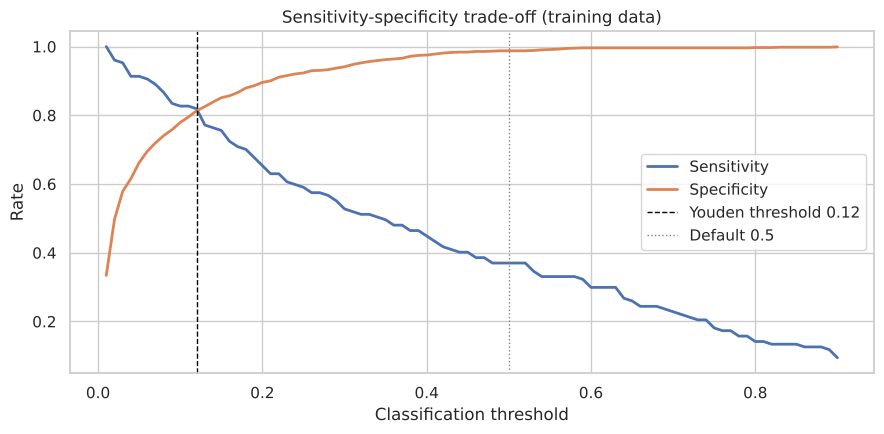

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sens, spec = [], []
ts = np.linspace(0.01, 0.9, 90)
for t in ts:
    pred = (p_train >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(train.Unhealthy, pred, labels=[0, 1]).ravel()
    sens.append(tp / (tp + fn)); spec.append(tn / (tn + fp))
ax.plot(ts, sens, lw=2, label="Sensitivity")
ax.plot(ts, spec, lw=2, label="Specificity")
ax.axvline(youden_thr, color="black", ls="--", lw=1, label=f"Youden threshold {youden_thr:.2f}")
ax.axvline(0.5, color="grey", ls=":", lw=1, label="Default 0.5")
ax.set(title="Sensitivity-specificity trade-off (training data)", xlabel="Classification threshold", ylabel="Rate")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "22_threshold_tradeoff.png", dpi=150); plt.show()

## 7. Calibration check

Are the predicted probabilities honest? Training days are grouped into 10 bins by predicted probability and the average prediction is compared with the observed share of unhealthy days (the idea behind the Hosmer-Lemeshow test).

In [12]:
cal = pd.DataFrame({"p": p_train, "y": train.Unhealthy})
cal["bin"] = pd.qcut(cal.p, 10, labels=False, duplicates="drop")
cal_tab = cal.groupby("bin").agg(days=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean"), observed=("y", "sum"))
cal_tab["expected"] = cal.groupby("bin")["p"].sum()
hl = (((cal_tab.observed - cal_tab.expected) ** 2) / (cal_tab.expected * (1 - cal_tab.mean_predicted))).sum()
hl_p = stats.chi2.sf(hl, len(cal_tab) - 2)
cal_tab.to_csv(TAB / "logistic_calibration.csv")
print(f"Hosmer-Lemeshow statistic = {hl:.2f}, df = {len(cal_tab) - 2}, p = {hl_p:.3f}  (p > 0.05: no evidence of poor calibration)")
cal_tab.round(3)

Hosmer-Lemeshow statistic = 4.38, df = 8, p = 0.822  (p > 0.05: no evidence of poor calibration)


,days,mean_predicted,observed_rate,observed,expected
bin,,,,,
0,119,0.0030,0.0000,0,0.3480
1,118,0.0050,0.0000,0,0.6300
2,118,0.0080,0.0000,0,0.9670
3,118,0.0130,0.0250,3,1.4860
4,118,0.0200,0.0250,3,2.4080
5,118,0.0380,0.0420,5,4.4390
6,118,0.0690,0.0850,10,8.1920
7,118,0.1250,0.1270,15,14.7250
8,118,0.2280,0.2120,25,26.8790
